# 02 — Preparação e integração dos dados

Este notebook lê as saídas geradas por `python -m src.build_dataset` e mostra as evidências de cada decisão de tratamento e integração. O script executa três módulos, nesta ordem:
* `ons.py`: lê e limpa os dados do ONS e gera as séries horária e diária.
* `clima.py`: usa a lista de usinas e a capacidade diária vindas do `ons.py` para definir os pontos de clima e calcular o vento ponderado.
* `feriados.py`: monta o calendário (finds de semana, feriados nacionais e carnaval).

Os parâmetros de todos eles ficam em `config.py`. O resultado final é a base final `data/processed/base_fc_eolico_ne_diario.parquet`: uma linha por dia (jan/2022 a out/2026), com FC (fator capacidade) eólico do Nordeste, o vento a 100 m (velocidade do vento medida a 100 metros de altura em relação ao chão, em m/s) e o calendário.

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src import clima, config as C

# Gera a base se ela ainda não existir (leva alguns minutos)
if not C.BASE_FINAL.exists():
    from src.build_dataset import main
    main()

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "lines.linewidth": 1.4})

base = pd.read_parquet(C.BASE_FINAL)
horario = pd.read_parquet(C.DIR_INTERIM / "fc_eolico_ne_horario.parquet")
pontos = pd.read_parquet(C.DIR_INTERIM / "pontos_clima.parquet")
mapa = pd.read_parquet(C.DIR_INTERIM / "usinas_pontos_clima.parquet")
qa = json.loads(C.RELATORIO_QUALIDADE.read_text(encoding="utf-8"))

## 1. Limpeza dos dados do ONS

A tabela abaixo mostra quantos registros (cada linha do arquivo do ONS é uma usina em uma hora) foram afetados em cada etapa da limpeza. Cada registro é uma usina em uma hora.

Quando um registro tem problema, ele sai da conta do FC por completo (da geração e da capacidade). Assim, ele não puxa o FC nem para baixo nem para cima.

In [2]:
linhas = {**qa["leitura_ons"], **qa["limpeza_ons"]}
pd.Series(linhas, name="valor").to_frame()

,valor
arquivos,58
linhas_lidas,8791056
texto_nao_numerico,0
linhas_eolicas_ne,5876256
usinas_conjuntos,190
instantes_arredondados,0
fora_do_periodo,0
duplicados_removidos,0
invalidos_geracao_ausente,552
invalidos_capacidade_ausente_ou_zero,3840


**Como ler a tabela:**

- Os 58 arquivos trazem as usinas do país inteiro. Ficam só as eólicas do Nordeste.
- Em alguns meses, os números vêm como texto. Todos foram convertidos para número, sem perda.
- Não há registros repetidos (mesma usina na mesma hora).
- O FC que vem do ONS fica 0 quando falta a capacidade. Por isso o FC é recalculado: geração ÷ capacidade.
- Geração acima de 110% da capacidade (em alguns casos, 12 vezes) é considerada erro e sai da conta.

> Das 4.523 linhas de registros inválidos, podem ser: geração vazia, capacidade vazia, geração negativa, geração passa de 110% da capacidade (gera mais do que consegue).

## 2. Por que prever o FC e não a geração

A capacidade eólica do Nordeste passou de 18 para 32 GW no período (+77%). Com mais usinas, a geração sobe mesmo sem mais vento. O FC mede quanto da capacidade foi usada, então não é afetado por esse crescimento.

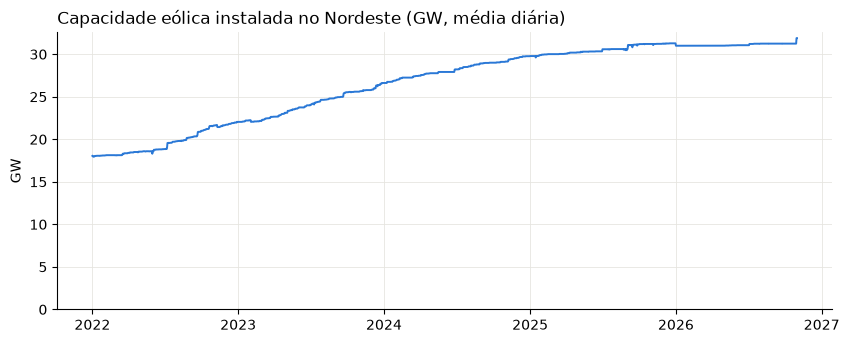

capacidade: 18.0 GW em 01/2022 -> 31.9 GW em 10/2026


In [3]:
d = base.set_index("data")
fig, ax = plt.subplots()
ax.plot(d.index, d["capacidade_mw"] / 1000, color=AZUL)
ax.set_title("Capacidade eólica instalada no Nordeste (GW, média diária)", loc="left")
ax.set_ylabel("GW"); ax.set_ylim(0)
plt.show()

print(f"capacidade: {d['capacidade_mw'].iloc[0]/1000:.1f} GW em {d.index[0]:%m/%Y} -> "
      f"{d['capacidade_mw'].iloc[-1]/1000:.1f} GW em {d.index[-1]:%m/%Y}")

## 3. De dados por hora para dados por dia

O FC do dia é a energia gerada no dia dividida pela energia máxima que as usinas poderiam ter gerado.

Todos os dias têm as 24 horas com dado, e em todos eles mais de 99% da capacidade tem registro válido. Nenhum dia precisou ser descartado.

In [4]:
print(base[["horas_com_dado", "cobertura", "n_usinas"]].describe().round(4).to_string())
print("dias com flag de qualidade:", (~base["qualidade_ok"]).sum())

       horas_com_dado  cobertura   n_usinas
count          1765.0  1765.0000  1765.0000
mean             24.0     0.9999   138.6312
std               0.0     0.0005     6.0930
min              24.0     0.9907   123.0000
25%              24.0     1.0000   137.0000
50%              24.0     1.0000   140.0000
75%              24.0     1.0000   142.0000
max              24.0     1.0000   148.0000
dias com flag de qualidade: 0


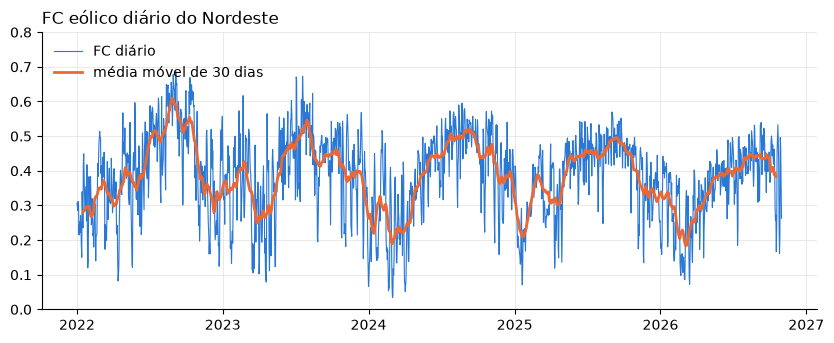

In [5]:
fig, ax = plt.subplots()
ax.plot(d.index, d["fc"], color=AZUL, linewidth=0.8, label="FC diário")
ax.plot(d.index, d["fc"].rolling(30, center=True).mean(), color=LARANJA, linewidth=2, label="média móvel de 30 dias")
ax.set_title("FC eólico diário do Nordeste", loc="left"); ax.set_ylim(0, 0.8); ax.legend(frameon=False, loc="upper left")
plt.show()

### Os dias de FC mais baixo são reais?

Para os dias de FC mais baixo, conferimos o vento do mesmo dia. Se o vento também foi fraco, o valor é real.

In [6]:
z = (d["fc"] - d["fc"].rolling(30, center=True, min_periods=10).mean()) / d["fc"].rolling(30, center=True, min_periods=10).std()
menores = d.assign(z_30d=z).nsmallest(6, "fc")[["fc", "z_30d", "vento_100m_ms", "dia_nao_util", "nome_feriado"]]
menores.round(3)

,fc,z_30d,vento_100m_ms,dia_nao_util,nome_feriado
data,,,,,
2024-03-01,0.034,-1.390,2.296,False,<NA>
2024-03-02,0.039,-1.372,2.442,True,<NA>
2024-04-02,0.051,-1.718,2.310,False,<NA>
2024-02-20,0.053,-1.221,2.866,False,<NA>
2024-02-22,0.062,-1.190,3.121,False,<NA>
2024-02-21,0.063,-1.176,2.951,False,<NA>


**Resultado:** esses dias (fev–abr/2024) tiveram vento abaixo de 3 m/s, enquanto a média do período é de 6,4 m/s. São dias reais de pouco vento e ficam na base.

## 4. Clima: de onde vem o vento de cada usina

Consultar o vento de cada uma das 190 usinas seria desnecessário, porque usinas vizinhas têm praticamente o mesmo vento. Por isso, as usinas próximas foram agrupadas em 20 pontos (algoritmo k-means, dando mais peso às usinas maiores). Cada usina usa o vento do seu ponto, consultado na API Open-Meteo.

Com 20 pontos, 93% da capacidade fica a menos de 50 km do seu ponto. É uma distância compatível com a grade dos dados de vento (ERA5), que tem cerca de 28 km.

In [7]:
print(qa["pontos_clima"])
pontos

{'n_pontos': 20, 'distancia_max_km': 113.9, 'capacidade_ate_50km': 0.933}


,ponto_id,lat,lon,estados,n_usinas,capacidade_mw,distancia_media_km,distancia_max_km
0,P01,-3.2097,-39.4715,CE,14,2106.3002,39.700000,78.0
1,P02,-3.5992,-41.0991,CE,4,350.9700,45.200000,76.0
2,P03,-4.6490,-37.5193,CE,6,812.8000,27.300000,44.8
3,P04,-5.1978,-37.0330,RN,12,2992.1920,18.516667,42.4
4,P05,-5.2562,-35.9279,RN,33,4157.0400,24.233333,62.5
5,P06,-5.6825,-36.1726,RN,8,3134.8000,23.050000,54.3
6,P07,-6.1763,-36.3477,RN,10,1713.3000,28.290000,71.3
7,P08,-6.8799,-36.6816,"PB,RN",6,1846.5400,19.716667,25.7
8,P09,-7.5042,-40.6636,PI,6,1478.7000,12.883333,15.1
9,P10,-7.9864,-40.6583,PI,5,1964.4000,10.340000,24.1


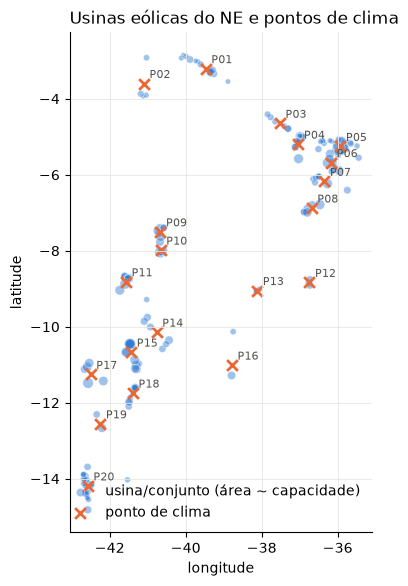

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(mapa["lon"], mapa["lat"], s=np.sqrt(mapa["capacidade_mw"]) * 2, color=AZUL, alpha=0.45,
           edgecolor="white", linewidth=0.6, label="usina/conjunto (área ~ capacidade)")
ax.scatter(pontos["lon"], pontos["lat"], marker="x", s=60, color=LARANJA, linewidth=2, label="ponto de clima")
for p in pontos.itertuples():
    ax.annotate(p.ponto_id, (p.lon, p.lat), xytext=(4, 4), textcoords="offset points", fontsize=8, color=CINZA)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_aspect("equal")
ax.set_title("Usinas eólicas do NE e pontos de clima", loc="left"); ax.legend(frameon=False, loc="lower right")
plt.show()

## 5. Clima: conferindo o fuso horário

O dicionário do ONS não diz se os horários estão em horário de Brasília ou em UTC (3 horas à frente). Os dados de vento vêm em UTC e foram convertidos para horário de Brasília.

Para conferir, comparamos o FC de cada hora com o vento deslocado de 1 a 6 horas para frente e para trás. O deslocamento com maior correlação mostra como as duas séries se alinham. Se o ONS estivesse em UTC, o pico apareceria em +3 h.

In [9]:
vento_h, _ = clima.vento_horario(pontos)
pesos = mapa.groupby("ponto_id")["capacidade_mw"].sum()
vh = (vento_h.assign(w=vento_h["ponto_id"].map(pesos))
              .groupby("din_instante")
              .apply(lambda g: np.average(g["vento_100m_ms"] ** 3, weights=g["w"]), include_groups=False)
              .rename("vento3"))
fc_h = horario.set_index("din_instante")["fc"]
lags = range(-6, 7)
corr = pd.Series({k: fc_h.corr(vh.shift(k)) for k in lags}, name="correlação")
print(corr.round(3).to_string())
print("deslocamento com maior correlação:", corr.idxmax(), "h")

-6    0.618
-5    0.662
-4    0.701
-3    0.730
-2    0.745
-1    0.747
0     0.736
1     0.711
2     0.678
3     0.642
4     0.607
5     0.576
6     0.550
deslocamento com maior correlação: -1 h


**Resultado:** o pico ficou em −1 h, e em +3 h a correlação é bem menor (0,64 contra 0,75). Então o ONS usa horário de Brasília.

A diferença de 1 hora acontece porque o ONS informa a média de cada hora, enquanto o vento é o valor do início da hora. Isso não afeta a base diária: muda só 1 das 24 horas de cada dia.

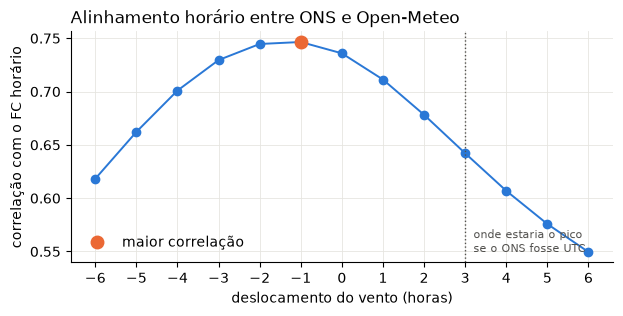

In [10]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(corr.index, corr.values, color=AZUL, marker="o", markersize=6)
ax.plot([corr.idxmax()], [corr.max()], marker="o", markersize=9, color=LARANJA, linestyle="none", label="maior correlação")
ax.axvline(3, color=CINZA, linestyle=":", linewidth=1)
ax.annotate("onde estaria o pico\nse o ONS fosse UTC", (3, corr.min()), xytext=(6, 0), textcoords="offset points", fontsize=8, color=CINZA)
ax.legend(frameon=False, loc="lower left")
ax.set_xlabel("deslocamento do vento (horas)"); ax.set_ylabel("correlação com o FC horário")
ax.set_title("Alinhamento horário entre ONS e Open-Meteo", loc="left"); ax.set_xticks(list(lags))
plt.show()

## 6. O vento explica o FC?

Conferência de que a junção dos dados faz sentido: quanto mais vento, maior o FC. A análise completa (H2) fica para a próxima etapa.

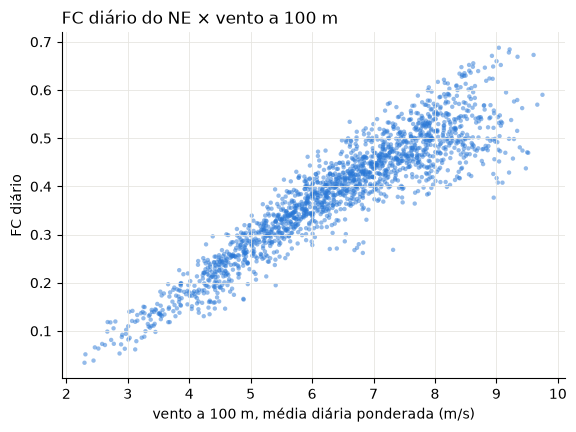

correlação de Pearson (vento): 0.925
correlação de Pearson (vento³): 0.862


In [11]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(base["vento_100m_ms"], base["fc"], s=10, color=AZUL, alpha=0.5, edgecolor="none")
ax.set_xlabel("vento a 100 m, média diária ponderada (m/s)"); ax.set_ylabel("FC diário")
ax.set_title("FC diário do NE × vento a 100 m", loc="left")
plt.show()
print("correlação de Pearson (vento):", round(base["fc"].corr(base["vento_100m_ms"]), 3))
print("correlação de Pearson (vento³):", round(base["fc"].corr(base["vento_100m_cubo"]), 3))

## 7. Feriados

Os feriados nacionais vêm da biblioteca `holidays` e são ligados aos dados pela data. O carnaval não é feriado oficial, mas o consumo de energia cai muito nesses dias, então ele tem uma coluna própria.

In [12]:
fer = base.loc[base["feriado_nacional"] | base["carnaval"], ["data", "nome_feriado", "carnaval", "fim_de_semana"]]
print("feriados nacionais:", base["feriado_nacional"].sum(), "| dias de carnaval:", base["carnaval"].sum(),
      "| dias não úteis:", base["dia_nao_util"].sum(), "de", len(base))
fer[fer["data"].dt.year == 2025]

feriados nacionais: 44 | dias de carnaval: 0 | dias não úteis: 537 de 1765


,data,nome_feriado,carnaval,fim_de_semana
1096,2025-01-01,Universal Fraternization Day,False,False
1203,2025-04-18,Good Friday,False,False
1206,2025-04-21,Tiradentes' Day,False,False
1216,2025-05-01,Worker's Day,False,False
1345,2025-09-07,Independence Day,False,True
1380,2025-10-12,Our Lady of Aparecida,False,True
1401,2025-11-02,All Souls' Day,False,True
1414,2025-11-15,Republic Proclamation Day,False,True
1419,2025-11-20,National Day of Zumbi and Black Awareness,False,False
1454,2025-12-25,Christmas Day,False,False


## 8. Base final

Cada linha é um dia e cada coluna é uma variável (formato *tidy*). A única coluna com valores vazios é `nome_feriado`, que só é preenchida em dias de feriado.

In [13]:
print(base.dtypes.to_string())
print()
print("ausentes por coluna:", base.isna().sum()[lambda s: s > 0].to_dict())
base.head()

data                              datetime64[us]
ano                                        int32
mes                                        int32
dia_semana                                 int32
fc                                       float64
geracao_mwmed                            float64
capacidade_mw                            float64
n_usinas                                   int64
horas_com_dado                             int64
cobertura                                float64
qualidade_ok                                bool
vento_100m_ms                            float64
vento_100m_cubo                          float64
vento_100m_desvio_entre_pontos           float64
pontos_clima                               int64
fim_de_semana                               bool
feriado_nacional                            bool
nome_feriado                              string
carnaval                                    bool
dia_nao_util                                bool
safra_ventos        

,data,ano,mes,dia_semana,fc,geracao_mwmed,capacidade_mw,n_usinas,horas_com_dado,cobertura,...,vento_100m_ms,vento_100m_cubo,vento_100m_desvio_entre_pontos,pontos_clima,fim_de_semana,feriado_nacional,nome_feriado,carnaval,dia_nao_util,safra_ventos
0,2022-01-01,2022,1,5,0.306041,5522.485375,18044.9052,123,24,1.000000,...,4.989974,223.762042,2.407613,19,True,True,Universal Fraternization Day,False,True,False
1,2022-01-02,2022,1,6,0.298936,5379.648250,17995.9927,123,24,0.997289,...,4.634340,160.242818,1.924482,19,True,False,<NA>,False,True,False
2,2022-01-03,2022,1,0,0.285210,5124.666250,17968.0427,123,24,0.995740,...,5.058819,181.947585,1.607849,19,False,False,<NA>,False,False,False
3,2022-01-04,2022,1,1,0.311567,5608.448792,18000.8052,123,24,0.997556,...,4.776020,175.473131,2.001386,19,False,False,<NA>,False,False,False
4,2022-01-05,2022,1,2,0.298650,5367.815417,17973.5802,123,24,0.996047,...,4.999338,166.556180,1.409241,19,False,False,<NA>,False,False,False


In [14]:
base.describe().T.round(3)

,count,mean,min,25%,50%,75%,max,std
data,1765,2024-06-01 00:00:00,2022-01-01 00:00:00,2023-03-18 00:00:00,2024-06-01 00:00:00,2025-08-16 00:00:00,2026-10-31 00:00:00,NaN
ano,1765.0,2023.930878,2022.0,2023.0,2024.0,2025.0,2026.0,1.387825
mes,1765.0,6.351275,1.0,3.0,6.0,9.0,12.0,3.378286
dia_semana,1765.0,3.001133,0.0,1.0,3.0,5.0,6.0,2.000566
fc,1765.0,0.385684,0.033989,0.305549,0.402237,0.473347,0.68769,0.122087
geracao_mwmed,1765.0,10217.662727,926.243375,7641.671708,10706.642625,13005.289375,17482.430333,3547.633818
capacidade_mw,1765.0,26559.448714,17968.0427,22481.7552,27916.0552,30606.0552,31895.195,4455.21728
n_usinas,1765.0,138.631161,123.0,137.0,140.0,142.0,148.0,6.092954
horas_com_dado,1765.0,24.0,24.0,24.0,24.0,24.0,24.0,0.0
cobertura,1765.0,0.99992,0.990682,1.0,1.0,1.0,1.0,0.000476
